##### Import Necessay Libraries

In [61]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

## 1. Business Understanding

## 2. Data Collection

##### Import Dataset

In [62]:
claimant_data =  pd.read_csv(filepath_or_buffer="assets/claimant.csv")
claimant_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


## 3. Data Understanding

- in the above attorney is the output and other are input

In [63]:
claimant_data.shape

(1340, 7)

In [64]:
claimant_data.isna().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [65]:
claimant_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

In [66]:
claimant_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [67]:
claimant_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   CASENUM   1340 non-null   int64  
 1   ATTORNEY  1340 non-null   int64  
 2   CLMSEX    1328 non-null   float64
 3   CLMINSUR  1299 non-null   float64
 4   SEATBELT  1292 non-null   float64
 5   CLMAGE    1151 non-null   float64
 6   LOSS      1340 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 73.4 KB


## 4. Data Prperation

#### 4.1 Preparing the entire dataset

In [68]:
claimant_data.dropna(inplace=True)

In [69]:
claimant_data.isna().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [70]:
claimant_data.shape

(1096, 7)

- the given data have 1340 records and after removing the null entries, current dataset have 1096 records

- 244 records have removed because of null entries

##### Note
- In data cleaning after cleaning the dta all the data should need to be in number, if in other formate make it in numbers

#### 4.2 Seperate input and outputs

##### Note
- during data clearning need to apply our common sense, to indentify required input featues which need to contribute for the ouptu

In [71]:
X = claimant_data.iloc[:,2:].reset_index(drop=True)
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1091,1.0,1.0,0.0,16.0,0.060
1092,1.0,1.0,0.0,46.0,3.705
1093,1.0,1.0,0.0,39.0,0.099
1094,1.0,0.0,0.0,8.0,3.177


In [72]:
y = claimant_data["ATTORNEY"]
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## 5. Model Buidling

In [73]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, shuffle=True,  stratify=y)

In [74]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
503,1.0,1.0,0.0,36.0,15.766
334,0.0,1.0,0.0,10.0,50.000
540,0.0,1.0,0.0,14.0,4.479
1088,1.0,1.0,0.0,3.0,0.950
104,1.0,1.0,0.0,48.0,0.345
...,...,...,...,...,...
572,1.0,1.0,0.0,43.0,8.490
861,1.0,1.0,0.0,86.0,1.694
846,1.0,1.0,0.0,6.0,0.000
215,1.0,1.0,0.0,30.0,0.877


In [75]:
logistic_model = LogisticRegression()

## 6. Model Training

In [76]:
logistic_model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## 7. Model Testing

#### 7.1. Training Data 

In [77]:
predicted_train_output = logistic_model.predict(X_train)
predicted_train_output

array([0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0,

#### 7.2 Test Data

In [78]:
predicted_test_output = logistic_model.predict(X_test)
predicted_test_output

array([0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1])

In [79]:
print(f"Actual Data: {y.value_counts()}")
print("-----")
print(f"Actual Data: {y.value_counts(normalize=True) * 100}")
print("===============================================")
print(f"y_train: {y_train.value_counts()}")
print(f"y_train: {y_train.value_counts(normalize=True) * 100}")
print("-----")
print("===============================================")
print(f"y_test: {y_test.value_counts()}")
print("-----")
print(f"y_test: {y_test.value_counts(normalize=True) * 100}")

Actual Data: ATTORNEY
0    578
1    518
Name: count, dtype: int64
-----
Actual Data: ATTORNEY
0    52.737226
1    47.262774
Name: proportion, dtype: float64
y_train: ATTORNEY
0    462
1    414
Name: count, dtype: int64
y_train: ATTORNEY
0    52.739726
1    47.260274
Name: proportion, dtype: float64
-----
y_test: ATTORNEY
0    116
1    104
Name: count, dtype: int64
-----
y_test: ATTORNEY
0    52.727273
1    47.272727
Name: proportion, dtype: float64


In [80]:
# result_list = (claimant_data["ATTORNEY"] == predicted_output).tolist()

# result_list.count(False)



## 8. Model Evaluation

In [91]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

#### 8.1 Training Data's Evaluation Matrics

##### 8.1.1 Accuracy Score

In [82]:
accuracy_score(y_true=y_train, y_pred=predicted_train_output)

0.7146118721461188

##### 8.1.2 Confustion Matrix

- confustion matrix is the matrix with the values between the actual ouput and the predicted output
- we are using confustion matrix to know the mis-classification counts done by my model during the tranning time and the test time


In [83]:
print(confusion_matrix(y_true=y_train, y_pred=predicted_train_output))

[[307 155]
 [ 95 319]]


##### 8.1.3 Classification Report

In [84]:
print(classification_report(y_true=y_train, y_pred=predicted_train_output))

              precision    recall  f1-score   support

           0       0.76      0.66      0.71       462
           1       0.67      0.77      0.72       414

    accuracy                           0.71       876
   macro avg       0.72      0.72      0.71       876
weighted avg       0.72      0.71      0.71       876



#### ROC Curve (ROC - Receiver Operating Characteristics)
#### AUC Curve (AUC - Area Under this Curve)

0.717516782734174


Text(0, 0.5, 'True Positive Rate')

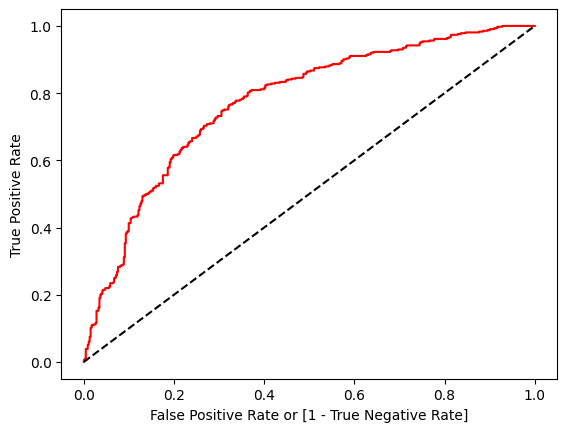

In [94]:
fpr, tpr, thresholds = roc_curve(y_train, logistic_model.predict_proba(X_train)[:, 1])

auc = roc_auc_score(y_train, predicted_train_output)
print(auc)

import matplotlib.pyplot as plt

plt.plot(fpr, tpr, color="red", label="logit model ( area = %.2f)" % auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate or [1 - True Negative Rate]")
plt.ylabel("True Positive Rate")

#### 8.2 Testing Data's Evalution Matrics

##### 8.2.1 Accuracy Score

In [85]:
accuracy_score(y_true=y_test, y_pred=predicted_test_output)

0.6727272727272727

##### 8.2.2 Confustion Matrix

In [86]:
print(confusion_matrix(y_true=y_test, y_pred=predicted_test_output))

[[74 42]
 [30 74]]


##### 8.2.3 Classification Report

In [87]:
print(classification_report(y_true=y_test, y_pred=predicted_test_output))

              precision    recall  f1-score   support

           0       0.71      0.64      0.67       116
           1       0.64      0.71      0.67       104

    accuracy                           0.67       220
   macro avg       0.67      0.67      0.67       220
weighted avg       0.68      0.67      0.67       220



## 9. Model Deployment

In [88]:
from pickle import dump, load

In [89]:
dump(obj=logistic_model, file=open("claimant.pkl", mode="wb"))

In [90]:
logistic_pkl = load(file=open("claimant.pkl", mode="rb"))